# Classical ML: dummy, logistic regression, BM25, tree, MLP, Naive Bayes, one-class SVM (notebook 02)

Part A walks through one seed-0 split with the pipeline from the course slides: dummy
baseline, TF-IDF logistic regression with a threshold picked on validation, BM25, a decision
tree, an MLP, Complement Naive Bayes and an unsupervised one-class SVM, then explanations and
error reading. Only training and validation rows
are used there. Part B runs the tuned experiment for all five split seeds (finished runs are
reused from `outputs/classical/`, so this is fast unless you delete them); the test split is
scored once per (model, seed) inside the run. Comparing and plotting the saved results is
notebook 04.

Run time: about 5 minutes for part A; part B is under a minute when the saved runs exist, or
about an hour if it has to recompute all 35 runs.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from modules import data_helper as dh
from modules import features as ft
from modules import models as md
from modules import eval_helper as ev
from modules import explain_helper as eh
from sklearn.inspection import permutation_importance
from modules import classical_runs as cr
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, precision_recall_curve

DATA = "../data/fake_job_postings.csv"

In [2]:
SEED = 0
SEEDS = [0, 1, 2, 3, 4]
SPLIT_PATH = "splits/seed0.npz"
OUT_CLASSICAL = "outputs/classical"

dh.seed_everything(SEED)
sns.set_theme(style="whitegrid")

# Part A: one split, validation only

## Setup: the seed-0 split

Load, clean, add features, and reuse the saved seed-0 split (Session 5: split
first, then fit on the training rows only).

In [3]:
# Load, clean (drop duplicates), add features.
df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))

# Reuse the saved split, or create and save it the first time.
if os.path.exists(SPLIT_PATH):
    splits = dh.load_splits(SPLIT_PATH, df)
else:
    splits = dh.make_splits(df, seed=SEED)
    dh.save_splits(SPLIT_PATH, splits, df)
assert not set(splits["train"]) & set(splits["val"]), "train/val row overlap"

# Frames and labels for the two splits this notebook uses (test stays untouched).
train = df.iloc[splits["train"]]
val = df.iloc[splits["val"]]
y_train = train["fraudulent"].to_numpy()
y_val = val["fraudulent"].to_numpy()

In [4]:
y_all = df["fraudulent"].to_numpy()
for name in ("train", "val", "test"):
    idx = splits[name]
    print(f"{name:5s}: {len(idx):6d} rows, {int(y_all[idx].sum()):4d} fraud ({y_all[idx].mean():.1%})")
print("test rows are listed for completeness; this notebook never scores them")

train:  10559 rows,  514 fraud (4.9%)
val  :   3520 rows,  171 fraud (4.9%)
test :   3520 rows,  171 fraud (4.9%)
test rows are listed for completeness; this notebook never scores them


## One helper for every model

The same three steps each time: fit on train, pick the decision threshold on
validation (never on test), then report train and validation side by side so the
generalisation gap is visible (Session 6). `ev.compare_table` names its second split
"test"; we pass validation metrics there and rename the columns below, so the test
rows are never touched.

In [5]:
# Everything the later cells need, keyed by model name.
fitted, thresholds, scores, results = {}, {}, {}, {}


def report(name, model):
    """Score a fitted model; the threshold is picked on validation only."""
    # Validation scores, then the threshold chosen on them.
    s_val = ev.score_of(model, val)
    # A dummy scores every ad the same, so it keeps its own predictions (threshold 0.5).
    thr = 0.5 if name.startswith("dummy") else ev.pick_threshold(y_val, s_val)

    # Train and validation metrics at that threshold, stored for the comparison table.
    results[name] = {"train": ev.evaluate(y_train, ev.score_of(model, train), thr),
                     "test": ev.evaluate(y_val, s_val, thr)}
    fitted[name], thresholds[name], scores[name] = model, thr, s_val

    # One small table for display.
    out = pd.DataFrame(results[name]).T.rename(index={"test": "val"})  # "test" slot holds validation
    out = out[["pr_auc", "roc_auc", "f1", "precision", "recall"]]
    out.insert(0, "model", name)
    return out

## The dummy baseline (Sessions 6/7)

Every model has to beat the dumb reference first: `dummy_majority` always predicts the
majority class (real). It reaches about 95% accuracy while catching no fraud at all, which is why
accuracy is not our metric; its PR-AUC equals the fraud rate (about 0.049), the floor for PR-AUC.
Its score is the same for every ad, so a tuned threshold would mean nothing; it keeps 0.5.

In [6]:
frames = [report(name, est.fit(train, y_train))
          for name, est in md.get_baselines(SEED).items()]
pd.concat(frames)

,model,pr_auc,roc_auc,f1,precision,recall
train,dummy_majority,0.048679,0.5,0.0,0.0,0.0
val,dummy_majority,0.048580,0.5,0.0,0.0,0.0


## Logistic regression on TF-IDF + engineered features

`modules/models.py` builds one Pipeline: TF-IDF over the joined text, one-hot and
ordinal encoded metadata, scaled numeric flags, then a `class_weight="balanced"`
logistic regression.

In [7]:
report("logreg", md.get_models(SEED)["logreg"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,logreg,0.979949,0.999025,0.915323,0.949791,0.883268
val,logreg,0.824794,0.980151,0.773163,0.852113,0.707602


### Confusion matrix on validation

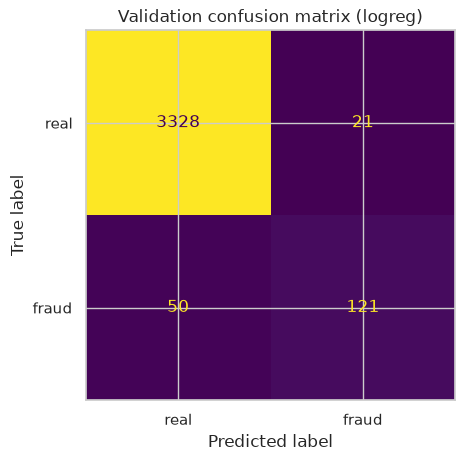

In [8]:
# Hard predictions at the validation-chosen threshold, drawn with sklearn's display.
pred_val = (scores["logreg"] >= thresholds["logreg"]).astype(int)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["real", "fraud"],
                                        colorbar=False)
plt.title("Validation confusion matrix (logreg)")
plt.show()

Reading: rows are the actual class, columns the predicted one; the diagonal holds
the correct calls.

### The threshold trade-off

Session 6: with an imbalanced target there is no free lunch between precision and
recall; the threshold is a business decision, and we pick it on validation.

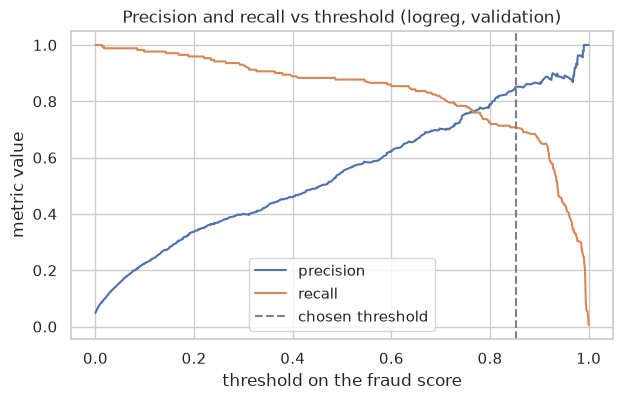

In [9]:
# Precision and recall at every distinct score (the last point has no threshold).
prec, rec, thr_grid = precision_recall_curve(y_val, scores["logreg"])

# Two curves plus the threshold that was actually chosen.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr_grid, prec[:-1], label="precision")
ax.plot(thr_grid, rec[:-1], label="recall")
ax.axvline(thresholds["logreg"], color="grey", linestyle="--", label="chosen threshold")
ax.set_xlabel("threshold on the fraud score")
ax.set_ylabel("metric value")
ax.set_title("Precision and recall vs threshold (logreg, validation)")
ax.legend()
plt.show()

Reading: the dashed line is the threshold picked on validation; moving it right can
only shrink the set of flagged ads.

## BM25 instead of TF-IDF

BM25 is the ranking function behind classic search engines. It differs from TF-IDF
in two ways: repeating a word has diminishing returns (saturating term frequency),
and long ads are discounted relative to the average ad length (length normalisation).
The vocabulary and everything else in the pipeline are identical, so any difference
in the numbers comes from the weighting alone.

In [10]:
report("logreg_bm25", md.get_models(SEED)["logreg_bm25"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,logreg_bm25,0.982686,0.999157,0.935211,0.903811,0.968872
val,logreg_bm25,0.827157,0.980638,0.778761,0.785714,0.771930


## Decision tree

Easy to read, prone to overfitting on sparse text. `tree_rules` prints the top
levels of the fitted tree; `top_tree_features` lists the features it leans on.

In [11]:
report("tree", md.get_models(SEED)["tree"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,tree,0.981589,0.999052,0.907084,0.860384,0.959144
val,tree,0.504271,0.886966,0.668394,0.600000,0.754386


In [12]:
print(eh.tree_rules(fitted["tree"], max_depth=3))

|--- binary__missing_company_profile <= 0.50
|   |--- text__encouraged <= 0.04
|   |   |--- text__process provide <= 0.05
|   |   |   |--- text__high school <= 0.05
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- text__high school >  0.05
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- text__process provide >  0.05
|   |   |   |--- text__professional <= 0.03
|   |   |   |   |--- class: 0
|   |   |   |--- text__professional >  0.03
|   |   |   |   |--- truncated branch of depth 2
|   |--- text__encouraged >  0.04
|   |   |--- text__growing <= 0.02
|   |   |   |--- text__looking <= 0.04
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- text__looking >  0.04
|   |   |   |   |--- class: 0
|   |   |--- text__growing >  0.02
|   |   |   |--- class: 0
|--- binary__missing_company_profile >  0.50
|   |--- ordinal__required_experience <= 1.62
|   |   |--- binary__has_company_logo <= 0.50
|   |   |   |--- text__web <= 0.05
|   |   |   |   |--- tru

In [13]:
eh.top_tree_features(fitted["tree"], k=10)

,term,importance
0,binary__missing_company_profile,0.293195
1,text__encouraged,0.144615
2,text__process provide,0.058810
3,text__high school,0.045802
4,ordinal__required_experience,0.039196
5,text__income,0.035713
6,text__real estate,0.024856
7,text__calls,0.019856
8,binary__has_company_logo,0.019425
9,text__telecommunication,0.016576


## MLP on the same features

A small sklearn neural network. It has no `class_weight`, so we rely on the ranking
of its scores plus the threshold picked on validation (Session 5).

In [14]:
report("mlp", md.get_models(SEED)["mlp"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,mlp,0.993849,0.998611,0.980431,0.986220,0.974708
val,mlp,0.899189,0.986176,0.856269,0.897436,0.818713


## Complement Naive Bayes

The classic text-classification baseline: word counts per class, with no feature interactions.
Complement NB is the variant designed for imbalanced classes (it learns each class from the
documents of all *other* classes). It needs non-negative inputs, which TF-IDF, one-hot flags and
the scaled counts are.

In [15]:
report("cnb", md.get_models(SEED)["cnb"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,cnb,0.503864,0.935303,0.519231,0.441417,0.630350
val,cnb,0.426505,0.908471,0.481793,0.462366,0.502924


## One-class SVM: can fraud be found without labels?

Anomaly detection view: learn what a *real* ad looks like from the real training ads only, then
flag ads that do not fit. The detector never sees a fraud example; the labels are used only to
leave the frauds out of its training data (and, in part B, to pick `nu`). An RBF kernel needs
dense, low-dimensional input, so the TF-IDF matrix is first reduced to 100 to 200 dimensions with
truncated SVD (as in LSA). The score is how far an ad lies outside the "normal" region.

In [16]:
report("ocsvm", md.get_models(SEED)["ocsvm"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,ocsvm,0.073258,0.584857,0.104003,0.057533,0.540856
val,ocsvm,0.066300,0.585633,0.125625,0.069410,0.660819


Is the fraud signal missing from these features, or does the "unusual = fraud" assumption fail?
Check: the same preprocessing and the same 200-dimensional SVD, but a supervised logistic
regression that is allowed to see the labels.

In [17]:
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

svd_lr = Pipeline([("pre", ft.make_preprocessor("tfidf")),
                   ("svd", TruncatedSVD(n_components=200, random_state=SEED)),
                   ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])
report("svd_logreg (check)", svd_lr.fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,svd_logreg (check),0.752694,0.979744,0.679552,0.712154,0.649805
val,svd_logreg (check),0.684692,0.959854,0.658610,0.681250,0.637427


Reading: if the supervised model on the very same features scores far above the one-class SVM,
the information is there and it is the anomaly assumption that fails: fraudulent ads are not
unusual ads; many are generic, template-like postings.

## All models side by side

Train versus validation PR-AUC per model; the gap column is the generalisation gap.
This is validation, not test: part B scores the test split once per (model, seed).

In [18]:
table = ev.compare_table(results).rename(columns=lambda c: c.replace("test_", "val_"))
table.sort_values("val_pr_auc", ascending=False)

,model,train_pr_auc,val_pr_auc,train_f1,val_f1,train_recall,val_recall,train_precision,val_precision,gap
4,mlp,0.993849,0.899189,0.980431,0.856269,0.974708,0.818713,0.986220,0.897436,0.094660
2,logreg_bm25,0.982686,0.827157,0.935211,0.778761,0.968872,0.771930,0.903811,0.785714,0.155528
1,logreg,0.979949,0.824794,0.915323,0.773163,0.883268,0.707602,0.949791,0.852113,0.155154
7,svd_logreg (check),0.752694,0.684692,0.679552,0.658610,0.649805,0.637427,0.712154,0.681250,0.068002
3,tree,0.981589,0.504271,0.907084,0.668394,0.959144,0.754386,0.860384,0.600000,0.477317
5,cnb,0.503864,0.426505,0.519231,0.481793,0.630350,0.502924,0.441417,0.462366,0.077359
6,ocsvm,0.073258,0.066300,0.104003,0.125625,0.540856,0.660819,0.057533,0.069410,0.006958
0,dummy_majority,0.048679,0.048580,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000099


## Hyper-parameter tuning (switched off)

Part B below runs the full random search over all models and five seeds:
grouped cross-validation on the training rows only, scoring PR-AUC (Session 7). The
flag below runs a tiny live version (`n_iter=3, cv=3`); keep it False during the
demo.

In [19]:
RUN_TUNING = False  # flip to True to run a small random search live (slow)

if RUN_TUNING:
    # Grouped CV on the training rows so duplicate descriptions cannot leak across folds.
    search = md.tune(md.get_models(SEED)["logreg"], md.PARAM_GRIDS["logreg"],
                     train, y_train, train["group"].to_numpy(),
                     n_iter=3, cv=3, seed=SEED)
    print("best params:", search.best_params_)
    print("CV PR-AUC:", round(float(search.best_score_), 3))

## Which words drive the logreg?

Session 6: read the model. `top_linear_terms` maps the coefficients back to feature
names recovered from the fitted ColumnTransformer.

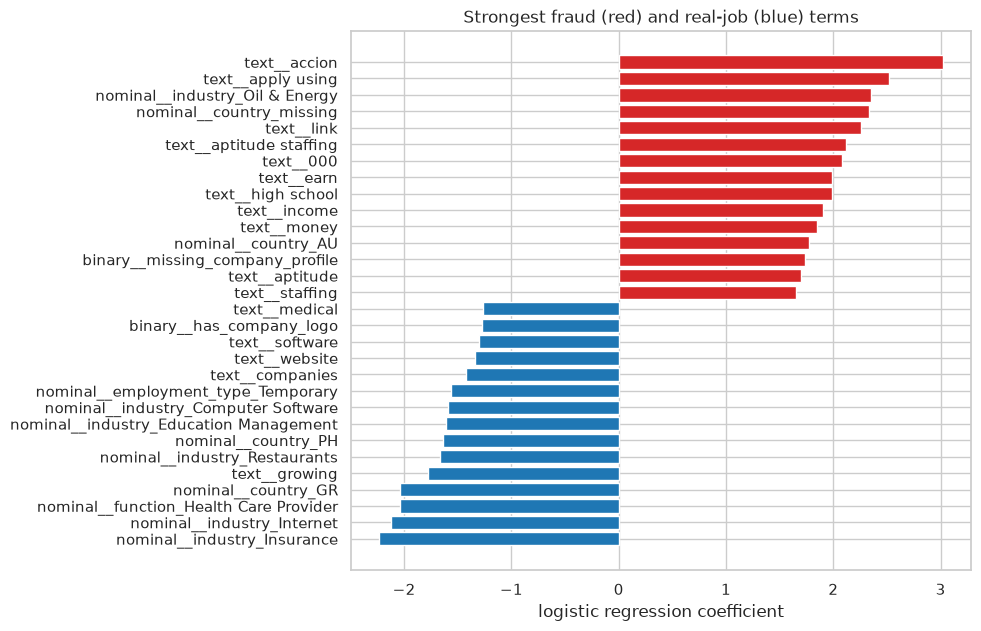

In [20]:
# The 15 strongest terms on each side, sorted so the bars read from blue to red.
terms = eh.top_linear_terms(fitted["logreg"], k=15).sort_values("coef")

# Horizontal bars: red pushes towards fraud, blue towards real.
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(terms["term"], terms["coef"],
        color=np.where(terms["coef"] > 0, "tab:red", "tab:blue"))
ax.set_xlabel("logistic regression coefficient")
ax.set_title("Strongest fraud (red) and real-job (blue) terms")
plt.show()

Reading: red bars push an ad towards fraud and blue bars towards real; bar length is
the coefficient, not the importance of a whole input column.

## Which columns matter? Permutation importance

Shuffle one raw input column at a time and see how much validation PR-AUC drops
(Session 6). We use a 1000-row validation sample and a single repeat to keep it
quick.

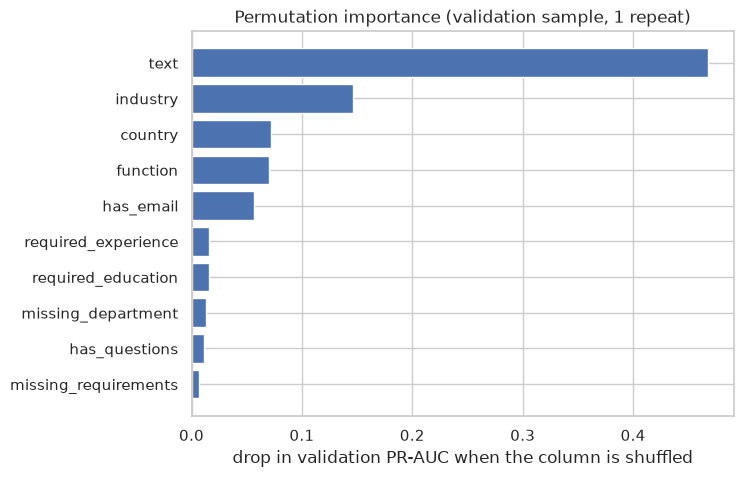

In [21]:
# Small validation sample and one repeat keep this quick. sklearn shuffles each raw column
# of the frame in turn and measures the drop in PR-AUC of the whole fitted pipeline.
val_sample = val.sample(min(1000, len(val)), random_state=SEED)
perm = permutation_importance(fitted["logreg"], val_sample, val_sample["fraudulent"].to_numpy(),
                              scoring="average_precision", n_repeats=1, random_state=SEED)

# Top 10 columns as a bar chart.
top = pd.Series(perm.importances_mean, index=val_sample.columns).nlargest(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values)
ax.set_xlabel("drop in validation PR-AUC when the column is shuffled")
ax.set_title("Permutation importance (validation sample, 1 repeat)")
plt.show()

Reading: the longer the bar, the more the model leaned on that single input column;
near-zero bars mean the column was barely used.

## Read the errors (Session 6)

The five most confident false positives (flagged, but real) and false negatives
(not flagged, but fraud) of the logreg on validation.

In [22]:
errors = eh.show_errors(val, y_val, scores["logreg"], thresholds["logreg"], k=5)
for _, e in errors.iterrows():
    print(f"[{e['error_type']}] score={e['score']:.3f}  title: {e['title']}")
    print(e["description"], "\n")

[false_positive] score=0.990  title: Customer Service 
Our client is seeking an Customer Service with 1 plus years of experience.The ideal candidate must have-1 plus years of experience in the support role-Calendar, scheduling, correspondence, phones-Conf 

[false_positive] score=0.988  title: Human Resources Administrator
JOB DESCRIPTIONThe Human Resources Administrator manages the day-to-day operations of the Human Resource office. The HR Administrator manages the administration of the human resources policies, proced 

[false_positive] score=0.977  title: Entry Level Controller: FT & PT
Are you looking to advance your bookkeeping career with a company that is growing at an exponential rate? Are you a pro with QuickBooks? Are you ready to step up to an Entry Level Controller or a Full 

[false_positive] score=0.977  title: Tankage
A company in oil &amp; gas that has grown into one of Malaysia’s leading integrated specialist technical services providers to the oil, gas and petrochemic

## Per-group check: employment type

Session 6: a model can look fine on average and still fail one group. Recall and
precision by employment type at the logreg's validation threshold.

In [23]:
# One row per prediction, then counts per employment type (missing is its own group).
pred_val = (scores["logreg"] >= thresholds["logreg"]).astype(int)
g = pd.DataFrame({"group": val["employment_type"].fillna("missing").to_numpy(),
                  "y": y_val, "pred": pred_val})
g["tp"] = g["y"] & g["pred"]
tab = g.groupby("group").agg(count=("y", "size"), positives=("y", "sum"),
                             flagged=("pred", "sum"), tp=("tp", "sum"))

# Recall = caught frauds / all frauds; precision = caught frauds / flagged ads.
tab["recall"] = tab["tp"] / tab["positives"]
tab["precision"] = tab["tp"] / tab["flagged"]
tab[["count", "positives", "recall", "precision"]]

,count,positives,recall,precision
group,,,,
Contract,254,9,0.222222,0.400000
Full-time,2274,93,0.752688,0.864198
Other,38,0,NaN,0.000000
Part-time,151,14,0.785714,0.785714
Temporary,65,1,1.000000,1.000000
missing,738,54,0.685185,0.925000


Reading: rows with few ads have noisy recall and precision; the count column says
how much to trust each row.

# Part B: tuned runs over five split seeds

For each seed and model `cr.run_classical` tunes on the training rows (random search, 4
candidates, 3-fold grouped CV, scoring PR-AUC), refits, picks the threshold on validation, and
scores validation and test once. One JSON + NPZ pair per (model, seed) goes to
`outputs/classical/`; pairs that already exist are skipped. Only validation numbers are printed.

In [24]:
RUN_CLASSICAL = True  # False: only read the saved results below
if RUN_CLASSICAL:
    df_all = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    cr.run_classical(df_all, SEEDS, out_dir=OUT_CLASSICAL, n_iter=4, cv=3)

seed 0: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 0 dummy_majority: already done, skipping
seed 0 logreg: already done, skipping
seed 0 logreg_bm25: already done, skipping
seed 0 tree: already done, skipping
seed 0 mlp: already done, skipping
seed 0 cnb: already done, skipping
seed 0 ocsvm: already done, skipping
seed 1: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 1 dummy_majority: already done, skipping
seed 1 logreg: already done, skipping
seed 1 logreg_bm25: already done, skipping
seed 1 tree: already done, skipping
seed 1 mlp: already done, skipping
seed 1 cnb: already done, skipping
seed 1 ocsvm: already done, skipping
seed 2: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 2 dummy_majority: already done, skipping
seed 2 logreg: already done, skipping
seed 2 logreg_bm25: already done, skipping
seed 2 tree: already done, skipping
seed 2 mlp: already done, skipping
seed 2 cnb: already done, skipping
seed 2 ocsvm: already done, skipping
seed 3: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 3 dummy_majority: already done, skipping
seed 3 logreg: already done, skipping
seed 3 logreg_bm25: already done, skipping
seed 3 tree: already done, skipping
seed 3 mlp: already done, skipping
seed 3 cnb: already done, skipping
seed 3 ocsvm: already done, skipping
seed 4: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 4 dummy_majority: already done, skipping
seed 4 logreg: already done, skipping
seed 4 logreg_bm25: already done, skipping
seed 4 tree: already done, skipping
seed 4 mlp: already done, skipping
seed 4 cnb: already done, skipping
seed 4 ocsvm: already done, skipping
